# Lightbeam Testing

In [28]:
import lightbeam as lb
import numpy as np
import matplotlib.pyplot as plt

from lightbeam.mesh import RectMesh3D

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

(5001, 81, 81)
(81, 81)


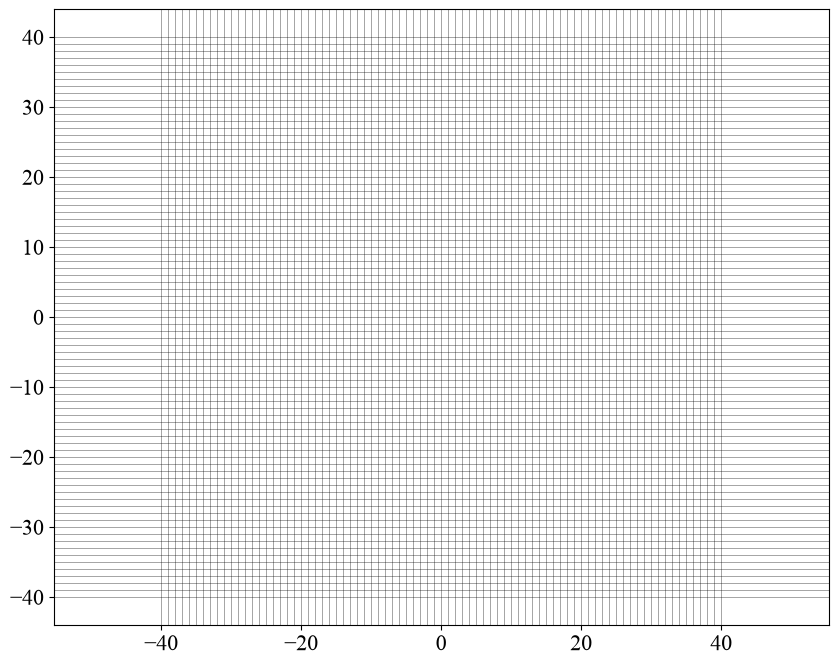

In [29]:
xw = 64 #um
yw= 64 #um
zw = 10000 #um
num_PML = 8 #grid units

ds = 1 #um
dz = 2 #um

_mesh = RectMesh3D(xw,yw,zw,ds,dz,num_PML)

### some properties and class functions ###

# shape
print(_mesh.shape)

# shape of transverse grid only
print(_mesh.xy.shape)

# plot the grid lines of the transverse mesh
_mesh.xy.plot_mesh()

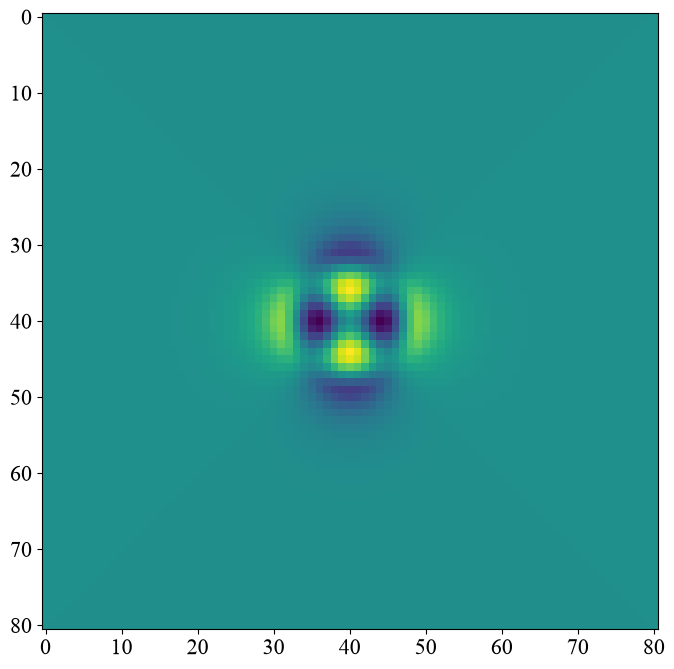

In [49]:
from csv import field_size_limit
from lightbeam import LPmodes
from lightbeam.misc import normalize

# Suppose our field is the LP11 mode with a core radius of 10 um
# We want to subdivide our mesh according to this field

l = 2
m = 2

# Initial setup to generate the LP11 field
x_grid, y_grid = _mesh.xg, _mesh.yg

r_core = 10 # [um]
wavelength = 1 # [um]
ncore = 1.5
nclad = 1.495

field = normalize( LPmodes.lpfield(x_grid, y_grid, l, m, r_core, wavelength, ncore, nclad) )

fig = plt.figure()
ax = fig.add_subplot()

ax.imshow(np.real(field))

plt.show()

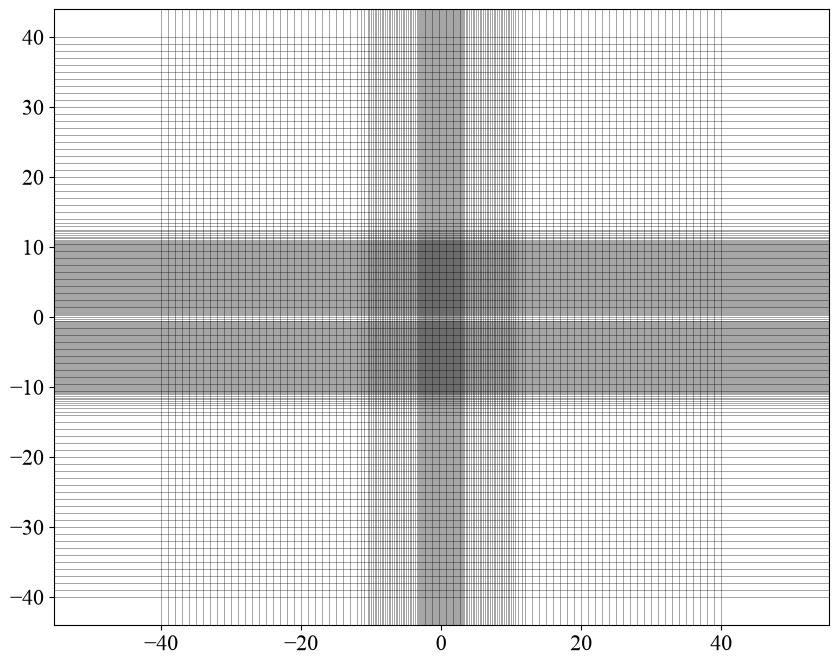

In [31]:
# Lower this parameter to incrase subdivisions. 
# Note that by default the code only allows for 6 subdivisions so
# that the minimum grid subdivision will be ds/2^6. 
# This can be altered under the parameter RectMesh3D.max_iters.
ref_val = 1e-3

_mesh.xy.refine_base(field, ref_val)
_mesh.xy.plot_mesh()

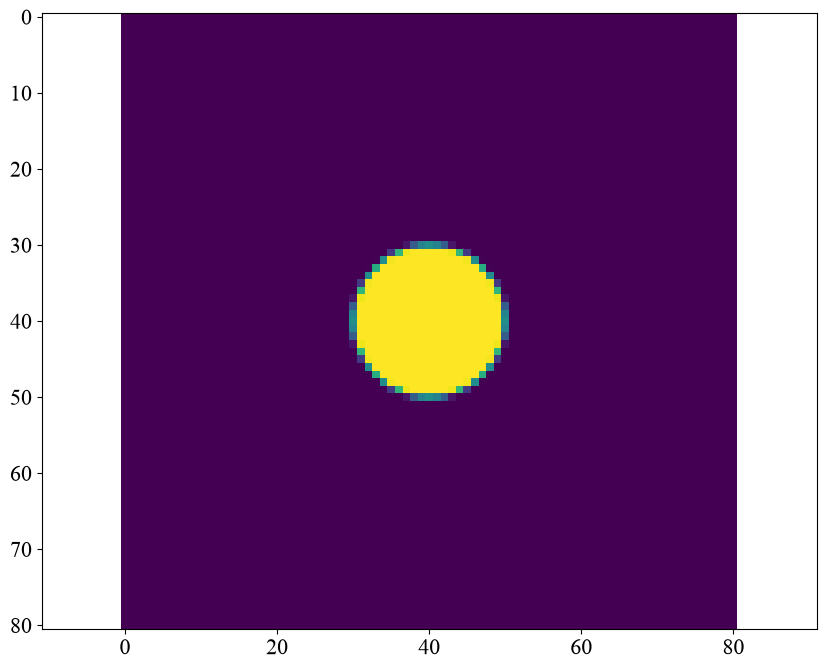

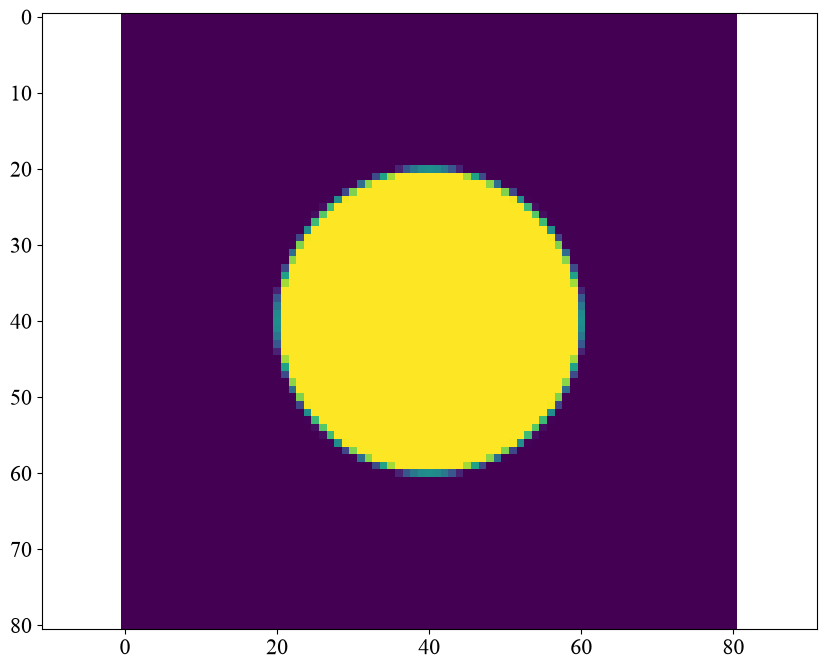

In [32]:
### Let's look at primitives first.### 
# We'll use the scaled_cyl as an example, though not all primitives need to be defined in exactly the same way.
# Note that scaled_cyl also requires us to give it a RectMesh2D object on which to compute refractive index distributions.

_mesh.xy.reinit(xw,yw)                            # reset the mesh to base, uniform grid. this func specifically will reset 
_mesh.xy.update(_mesh.xy.rfacxa,_mesh.xy.rfacya)    # the grid refinement factors, rfacxa and rfacya

import lightbeam.optics as optics

# initialization params #

xy = [0,0] # where the center of the cylinder is located at z=0.
r = 10 # make the initial radius 10 um
z_ex = 1000 # make the cylinder 1000 um long
n = 1.5 # set the refractive index to 1.5
nb = 1.49 # set the background index to 1.45
final_scale = 2 # set the final cross-sectional scale to 2, so the cylinder grows by a factor of 2

# instantiation #

cyl = optics.scaled_cyl(xy,r,z_ex,n,nb,final_scale=final_scale)
cyl.xymesh = _mesh.xy # pass in the mesh

out = np.zeros(_mesh.xy.shape)

# show structure at z=0
# note that this function computes (refractive index)^2, since that is what's used in the beam prop algorithm.
cyl.set_IORsq(out,0)
plt.imshow(out,vmax=n*n,vmin=nb*nb)
plt.axis('equal')
plt.show()

# show structure at z=1000
cyl.set_IORsq(out,1000)
plt.imshow(out,vmax=n*n,vmin=nb*nb)
plt.axis('equal')
plt.show()